<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 20: Probabilistic PCA and Reconstruction Analysis

**Category**: CO4 – Linear Factor Models and Probabilistic Graphical Models  
**Objective**: Implement Probabilistic PCA using maximum likelihood factor estimation and evaluate reconstruction error across latent dimensions.


### Task 1: Formulate Probabilistic PCA (PPCA) Generative Model


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Model: x = W*z + mu + epsilon, where z ~ N(0, I), epsilon ~ N(0, sigma^2 * I)
np.random.seed(42)
N, D = 250, 6
mu_true = np.array([1.2, -0.8, 0.5, 2.0, -1.5, 0.0])
# Rank-2 ground-truth generative matrix
W_true = np.array([
    [0.9, 0.1],
    [-0.7, 0.5],
    [0.4, 0.8],
    [0.8, -0.4],
    [-0.6, -0.6],
    [0.2, 0.7]
])
sigma_true = 0.25

z_lat = np.random.randn(N, 2)
noise_eps = np.random.randn(N, D) * sigma_true
X_ppca = np.dot(z_lat, W_true.T) + mu_true + noise_eps

print(f"Synthesized PPCA Observables (Shape: {X_ppca.shape})")
print("True Factor Loading Matrix Shape (D x q):", W_true.shape)


Synthesized PPCA Observables (Shape: (250, 6))
True Factor Loading Matrix Shape (D x q): (6, 2)


### Task 2: Maximum Likelihood PPCA Estimation and Reconstruction Error


In [2]:
def fit_ppca(X, q):
    N, D = X.shape
    mu = np.mean(X, axis=0)
    X_cent = X - mu
    S = np.dot(X_cent.T, X_cent) / N

    eigvals, eigvecs = np.linalg.eigh(S)
    sort_idx = np.argsort(eigvals)[::-1]
    eigvals = eigvals[sort_idx]
    eigvecs = eigvecs[:, sort_idx]

    # Noise variance sigma^2 estimate
    sigma_sq = np.mean(eigvals[q:])
    # Loading matrix W estimate
    U_q = eigvecs[:, :q]
    Lambda_q = np.diag(eigvals[:q])
    W_est = np.dot(U_q, np.sqrt(Lambda_q - sigma_sq * np.eye(q)))

    # Posterior mean latent representation E[z|x]
    M = np.dot(W_est.T, W_est) + sigma_sq * np.eye(q)
    M_inv = np.linalg.inv(M)
    Ez = np.dot(X_cent, np.dot(W_est, M_inv))

    # Reconstruction: x_hat = Ez * W^T + mu
    X_reconstructed = np.dot(Ez, W_est.T) + mu
    mse = np.mean((X - X_reconstructed)**2)
    return W_est, sigma_sq, X_reconstructed, mse

q_dims = list(range(1, D))
reconstruction_errors = []

for q in q_dims:
    _, s2, _, err = fit_ppca(X_ppca, q)
    reconstruction_errors.append(err)
    print(f"Latent Dimension q = {q}: Reconstruction MSE = {err:.5f} (Est σ² = {s2:.5f})")


Latent Dimension q = 1: Reconstruction MSE = 0.34161 (Est σ² = 0.39806)
Latent Dimension q = 2: Reconstruction MSE = 0.04173 (Est σ² = 0.06169)
Latent Dimension q = 3: Reconstruction MSE = 0.03853 (Est σ² = 0.05914)
Latent Dimension q = 4: Reconstruction MSE = 0.03486 (Est σ² = 0.05615)
Latent Dimension q = 5: Reconstruction MSE = 0.03205 (Est σ² = 0.05381)


### Task 3: Reconstruction Fidelity Curve vs. Latent Dimensionality


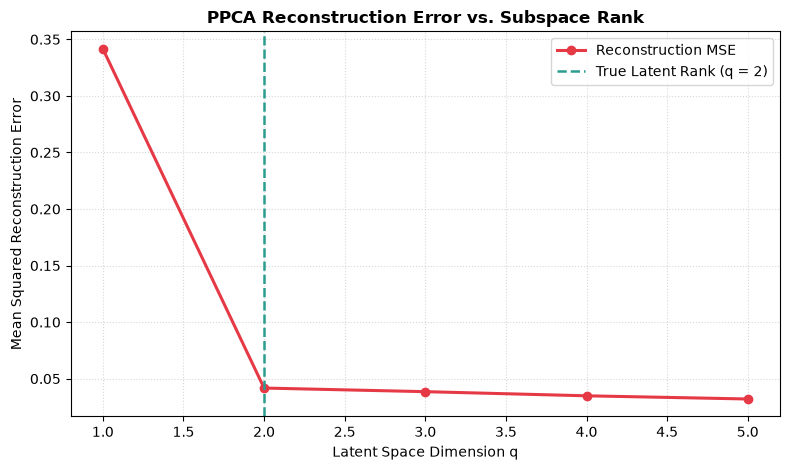

In [3]:
plt.figure(figsize=(8, 4.8))
plt.plot(q_dims, reconstruction_errors, color='#e63946', marker='o', lw=2.2, label='Reconstruction MSE')
plt.axvline(2, color='#2a9d8f', linestyle='--', lw=1.8, label='True Latent Rank (q = 2)')
plt.title("PPCA Reconstruction Error vs. Subspace Rank", fontweight='bold')
plt.xlabel("Latent Space Dimension q")
plt.ylabel("Mean Squared Reconstruction Error")
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
